# BRFSS 2015 · classer les réponses à une enquête de santé

Peut-on classer les personnes qui déclarent un prédiabète ou un diabète devant les autres répondants ? La classe positive est minoritaire. Le critère principal sera la **précision moyenne (AP)**, qui évalue le classement sur plusieurs seuils.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ml_workflow as mlw

mlw.get_environment_info()

{'python': '3.12.14',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2'}

## 1. Data import and exploration

In [2]:
DATA_PATH = Path("datasets/dbh/diabetes_binary_health_indicators_BRFSS2015.csv")
X, y = mlw.load_dataset("DHI", DATA_PATH, "Diabetes_binary")

253,680 observations, 21 features
Missing feature values: 0


,count,mean,std,min,25%,50%,75%,max,dtype,missing
HighBP,253680.0,0.429,0.495,0.0,0.0,0.0,1.0,1.0,float64,0
BMI,253680.0,28.382,6.609,12.0,24.0,27.0,31.0,98.0,float64,0
GenHlth,253680.0,2.511,1.068,1.0,2.0,2.0,3.0,5.0,float64,0
Age,253680.0,8.032,3.054,1.0,6.0,8.0,10.0,13.0,float64,0
Education,253680.0,5.050,0.986,1.0,4.0,5.0,6.0,6.0,float64,0
Income,253680.0,6.054,2.071,1.0,5.0,7.0,8.0,8.0,float64,0


,count,proportion
Diabetes_binary,,
0.000000,218334,86.1%
1.000000,35346,13.9%


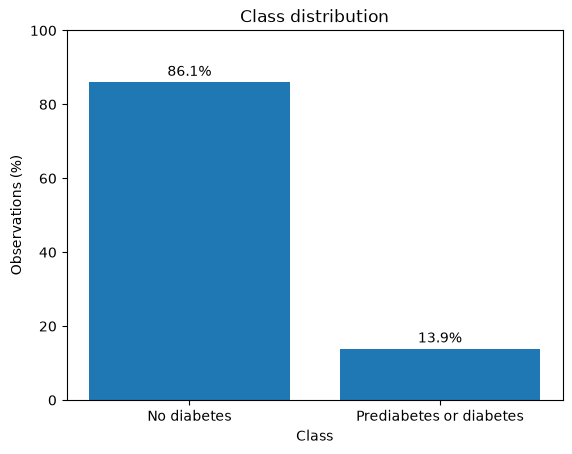

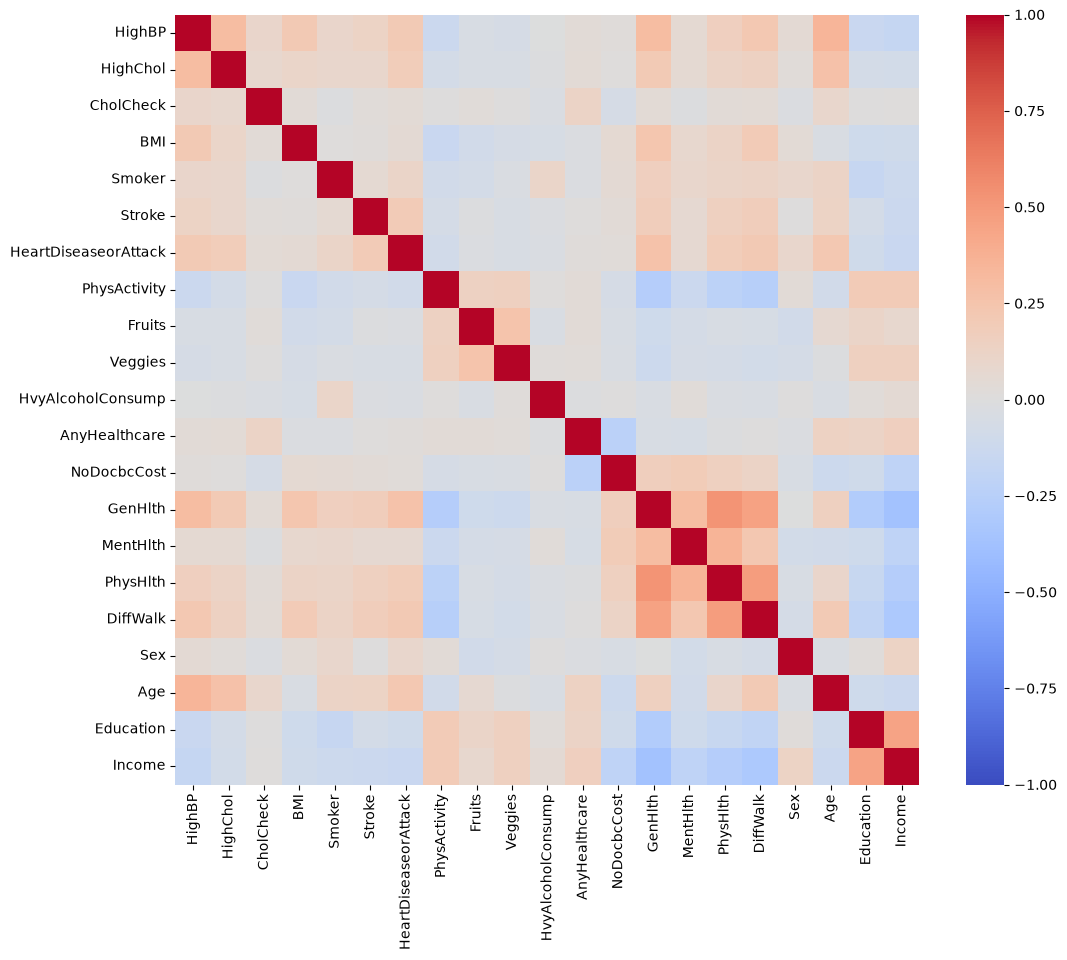

In [3]:
print(f"{X.shape[0]:,} observations, {X.shape[1]} features")
summary = mlw.summarize_dataset(X)
print("Missing feature values:", summary["missing"].sum())
display(summary.loc[['HighBP', 'BMI', 'GenHlth', 'Age', 'Education', 'Income']].round(3))

distribution = mlw.get_class_distribution(y)
display(distribution.style.format({"proportion": "{:.1%}"}))
mlw.plot_class_distribution(y, labels={0: "No diabetes", 1: "Prediabetes or diabetes"})
plt.show()

mlw.plot_correlation_matrix(X)
plt.show()

**Commentaire :** Sur 253 680 observations, 35 346 appartiennent à la classe positive (13,9 %). Prédire systématiquement la classe négative donnerait déjà 86,1 % d’exactitude, avec un rappel nul pour les cas positifs. Nous suivrons donc le rappel de la classe positive lors de la comparaison des modèles.

Les statistiques se lisent selon le type de variable. Pour `HighBP`, codée 0 ou 1, la moyenne de 0,429 indique que 42,9 % des personnes interrogées déclarent une hypertension. L’IMC médian vaut 27. L’âge, la santé générale, l’éducation et le revenu sont codés en catégories ordonnées. La régression impose un effet linéaire par changement de catégorie, tandis que les arbres peuvent apprendre des ruptures.

## 2. Cleaning and split

In [4]:
rows_before = len(X)
exact_repeats = pd.concat([X, y], axis=1).duplicated().sum()
X, y = mlw.clean_dataset(X, y, drop_duplicates=False)
print(f"Rows before: {rows_before:,} | Rows after: {len(X):,} | Exact repeats: {exact_repeats:,}")

Rows before: 253,680 | Rows after: 253,680 | Exact repeats: 24,206


**Commentaire :** Les 24 206 répétitions exactes sont conservées. Plusieurs personnes peuvent donner les mêmes réponses au questionnaire et appartenir à la même classe. Toutes les cibles sont renseignées et aucune variable ne nécessite d’imputation.

In [5]:
X_train, X_test, y_train, y_test = mlw.split_dataset(X, y)
print(f"Training: {len(X_train):,} | Test: {len(X_test):,}")

Training: 202,944 | Test: 50,736


**Commentaire :** Le tirage stratifié conserve la fréquence de la classe positive. Les 21 indicateurs disponibles ne permettent pas de séparer les personnes par identifiant ou par site. La portée temporelle du test est limitée à l’enquête de 2015.

## 3. Preprocessing and feature selection

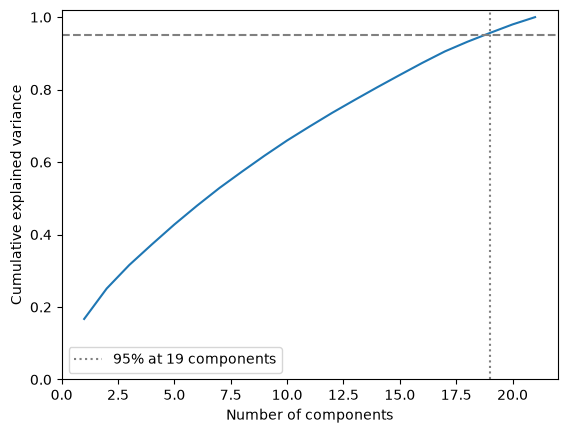

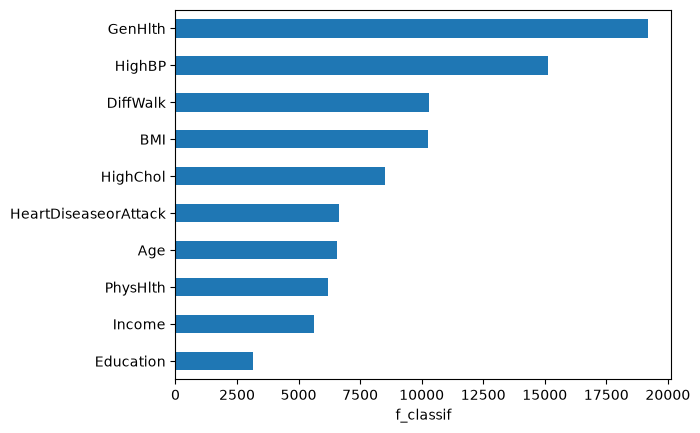

Highest ANOVA scores: GenHlth, HighBP, DiffWalk


In [6]:
mlw.plot_pca_explained_variance(X_train)
plt.show()
scores = mlw.compute_feature_scores(X_train, y_train, method="f_classif")
mlw.plot_feature_scores(scores, top_n=10)
plt.show()
print("Highest ANOVA scores:", ", ".join(scores.index[:3]))

**Commentaire :** Il faut 19 composantes sur 21 pour conserver 95 % de la variance. Le gain en dimension est faible et les axes perdent le sens des indicateurs d’origine. La santé générale et l’hypertension figurent en tête du classement univarié. Cette association transversale ne permet pas une interprétation causale.

## 4. Model selection on training folds

Les cinq plis comparent une référence majoritaire, une régression logistique, un arbre de décision et un ensemble d’arbres entraînés séquentiellement (boosting). La médiane et la standardisation sont estimées dans chaque pli. Le meilleur réglage de chaque famille est ensuite réajusté sur tout l’entraînement.

In [7]:
SCORING = "average_precision"
cv_results, models = mlw.fit_candidates(
    X_train, y_train, scoring=SCORING,
    class_weight="balanced",
)
winner = cv_results.iloc[0]["model"]
display(cv_results.round(4))
print("Selected on training folds:", winner)

,model,features,parameters,CV mean,CV SD
10,Boosting,All features,{'model__max_leaf_nodes': 31},0.4351,0.0079
9,Boosting,All features,{'model__max_leaf_nodes': 7},0.4313,0.0065
1,Logistic,All features,{'model__C': 0.1},0.4060,0.0041
3,Logistic,All features,{'model__C': 1.0},0.4060,0.0041
8,Tree,All features,{'model__max_depth': 8},0.4019,0.0059
2,Logistic,Top 10,{'model__C': 0.1},0.3996,0.0040
4,Logistic,Top 10,{'model__C': 1.0},0.3996,0.0040
5,Logistic,PCA 95%,{'model__C': 0.1},0.3994,0.0039
6,Logistic,PCA 95%,{'model__C': 1.0},0.3994,0.0039
7,Tree,All features,{'model__max_depth': 3},0.3126,0.0038


Selected on training folds: Boosting


**Commentaire :** Sur les mêmes plis, la meilleure régression obtient une AP de 0,406 avec 21 variables, contre 0,400 avec les dix mieux classées et 0,399 avec la PCA. Ici, les deux réductions perdent un peu de signal discriminant. Les écarts-types décrivent la variation entre plis.

### Effet de la pondération

La pondération change-t-elle le classement des répondants ou surtout la décision au seuil par défaut ? On isole ce facteur sur la même régression et les mêmes plis d’entraînement.

In [8]:
folds = mlw.training_folds(X_train, y_train)
checks = {}
for label, weight in [("Uniform weights", None), ("Balanced weights", "balanced")]:
    probe = mlw.build_pipeline(mlw.get_models(class_weight=weight)["Logistic"])
    checks[label] = mlw.cross_validate_model(
        probe, X_train, y_train, scoring=["precision", "recall", "average_precision"], cv=folds,
    ).mean()
display(pd.DataFrame(checks).T.round(4))

,precision,recall,average_precision
Uniform weights,0.5391,0.1580,0.4076
Balanced weights,0.3118,0.7656,0.4060


**Commentaire :** À pondération équilibrée, le rappel moyen passe de 15,8 % à 76,6 %, tandis que la précision passe de 53,9 % à 31,2 %. L’AP varie peu (0,408 à 0,406). La pondération déplace surtout le compromis au seuil par défaut. Elle ne transforme pas ce score en probabilité clinique calibrée.

## 5. Held-out evaluation

,Majority,Logistic,Tree,Boosting
accuracy,0.8607,0.7315,0.7053,0.7203
balanced_accuracy,0.5000,0.7439,0.7394,0.7502
precision,0.0000,0.3108,0.2926,0.3056
recall,0.0000,0.7611,0.7865,0.7916
f1,0.0000,0.4413,0.4265,0.4410
f0.5,0.0000,0.3525,0.3346,0.3484
roc_auc,0.5000,0.8196,0.8134,0.8269
average_precision,0.1393,0.3926,0.3934,0.4236


,TN,FP,FN,TP
Majority,43667,0,7069,0
Logistic,31735,11932,1689,5380
Tree,30226,13441,1509,5560
Boosting,30951,12716,1473,5596


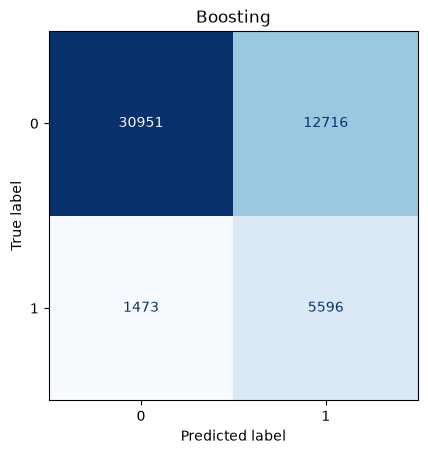

In [9]:
results = mlw.compare_models(models, X_test, y_test)
count_columns = ["TN", "FP", "FN", "TP"]
display(results.drop(columns=count_columns).T.round(4))
display(results[count_columns].astype(int))
mlw.plot_confusion_matrix(models[winner], X_test, y_test)
plt.title(winner)
plt.show()

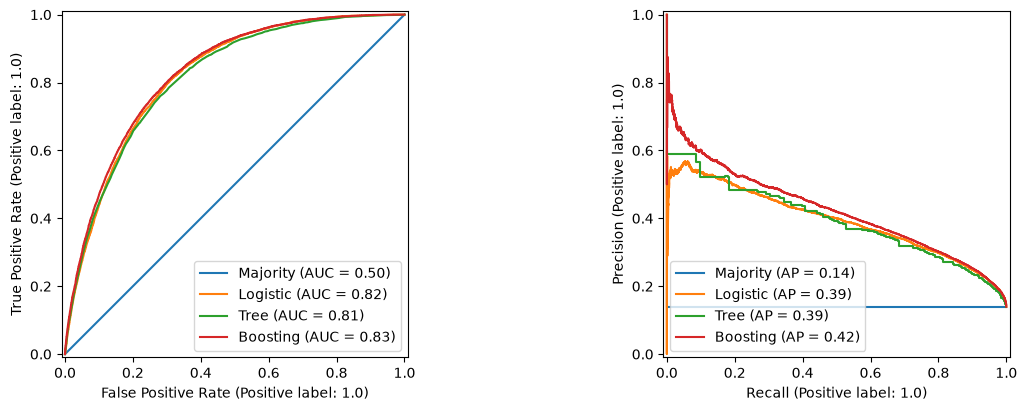

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
mlw.plot_roc_curves(models, X_test, y_test, ax=axes[0])
mlw.plot_precision_recall_curves(models, X_test, y_test, ax=axes[1])
plt.show()

## 6. Discussion

**Choix final.** Je retiens le boosting à 31 feuilles maximales pour classer les répondants. Sur le test, son AP de 0,424 dépasse celle de la régression (0,393) et celle du score constant (0,139). Au seuil par défaut du modèle pondéré, il retrouve 5 596 cas positifs sur 7 069, au prix de 12 716 faux positifs. Ce seuil impose donc beaucoup de vérifications pour chaque cas identifié.

**Limite.** La cible et plusieurs indicateurs sont déclaratifs et contemporains. Le modèle décrit une association dans l’enquête de 2015. Une utilisation pour anticiper un diagnostic futur demanderait un suivi longitudinal, une validation externe et un seuil choisi sur des données de validation selon le coût des erreurs.